In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [255]:
def r(S, S_half, rho, r_min):
    return (1-r_min) / (np.exp((S-S_half)/rho) + 1) + r_min

# def cascade_size(gamma, S, K, rng):
#     m = min(gamma*S/K, 0.999)
#     assert(m<1)
#     Z_sum = 0
#     Z = 1
#     while Z != 0:
#         Z_sum += Z
#         Z = rng.poisson(m*Z)
#     return Z_sum

def cascade_size(gamma, S, K, rng, k=1):
    m = min(gamma*S/K, 0.999)
    Z_sum = 0
    Z = 1
    while Z != 0:
        Z_sum += Z
        Z = rng.binomial(k*Z, m/k)   # Z sweeps, each Binomial(k, m/k): same mean m, less spread
    return Z_sum

def L(S, sweeps, r, rng):
    return min(S, rng.binomial(sweeps, r))

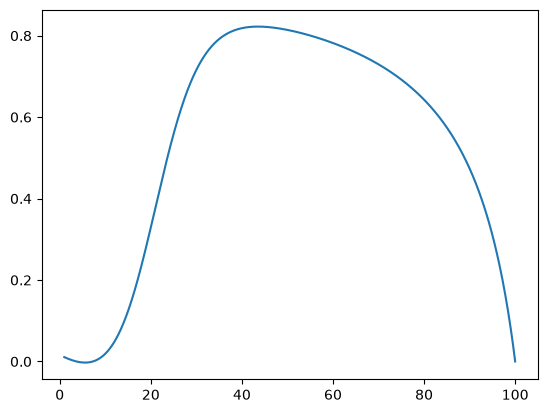

In [268]:
S_half = 20
gamma = 0.03
rho = 5
r_min = 0.1
K = 3/(1-r_min)
S_high = int(round(K*(1-r_min)/gamma))
T=100000
S_dist = np.linspace(1, 100, 1000)
f_theory = 1 - r(S_dist, S_half, rho, r_min)/(1-(S_dist*gamma/K))
rng = np.random.default_rng(123)
plt.plot(S_dist, f_theory)
plt.show()

In [269]:
S_hist = np.zeros(T)
S = 1
S_hist[0] = S
for i in range(T-1):
    g = 1
    r_val = r(S, S_half, rho, r_min)
    sweeps = cascade_size(gamma, S, K, rng)
    L_val = L(S, sweeps, r_val, rng)
    ds = g - L_val
    S += ds
    S_hist[i+1] = S


100


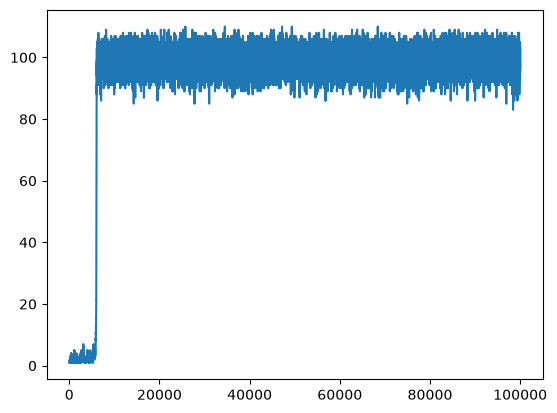

In [270]:
n = np.linspace(0, T, T)
plt.plot(n, S_hist)
print(S_high)

In [3]:
def r(q, F):
    return q**F

def c(r, S, S_c):
    return r/(1-S/S_c)

def G(b, r, S, S_c):
    return b*(1-r)/(1-S/S_c)

def E(j, gamma, S, S_c):
    return j*gamma/(1-S/S_c)

def j(a, F):
    return a*(F-1)

def dS(c):
    return 1 - c

def dF(c, F, G, E, S):
    return ((1-c)*(1-F) + G - E)/S